In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('wine-clustering.csv')
df

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Alcohol               178 non-null    float64
 1   Malic_Acid            178 non-null    float64
 2   Ash                   178 non-null    float64
 3   Ash_Alcanity          178 non-null    float64
 4   Magnesium             178 non-null    float64
 5   Total_Phenols         178 non-null    float64
 6   Flavanoids            178 non-null    float64
 7   Nonflavanoid_Phenols  178 non-null    float64
 8   Proanthocyanins       178 non-null    float64
 9   Color_Intensity       178 non-null    float64
 10  Hue                   178 non-null    float64
 11  OD280                 178 non-null    float64
 12  Proline               178 non-null    float64
dtypes: float64(13)
memory usage: 18.2 KB


In [3]:
df.isnull().sum()

Alcohol                 0
Malic_Acid              0
Ash                     0
Ash_Alcanity            0
Magnesium               0
Total_Phenols           0
Flavanoids              0
Nonflavanoid_Phenols    0
Proanthocyanins         0
Color_Intensity         0
Hue                     0
OD280                   0
Proline                 0
dtype: int64

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df.describe()

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


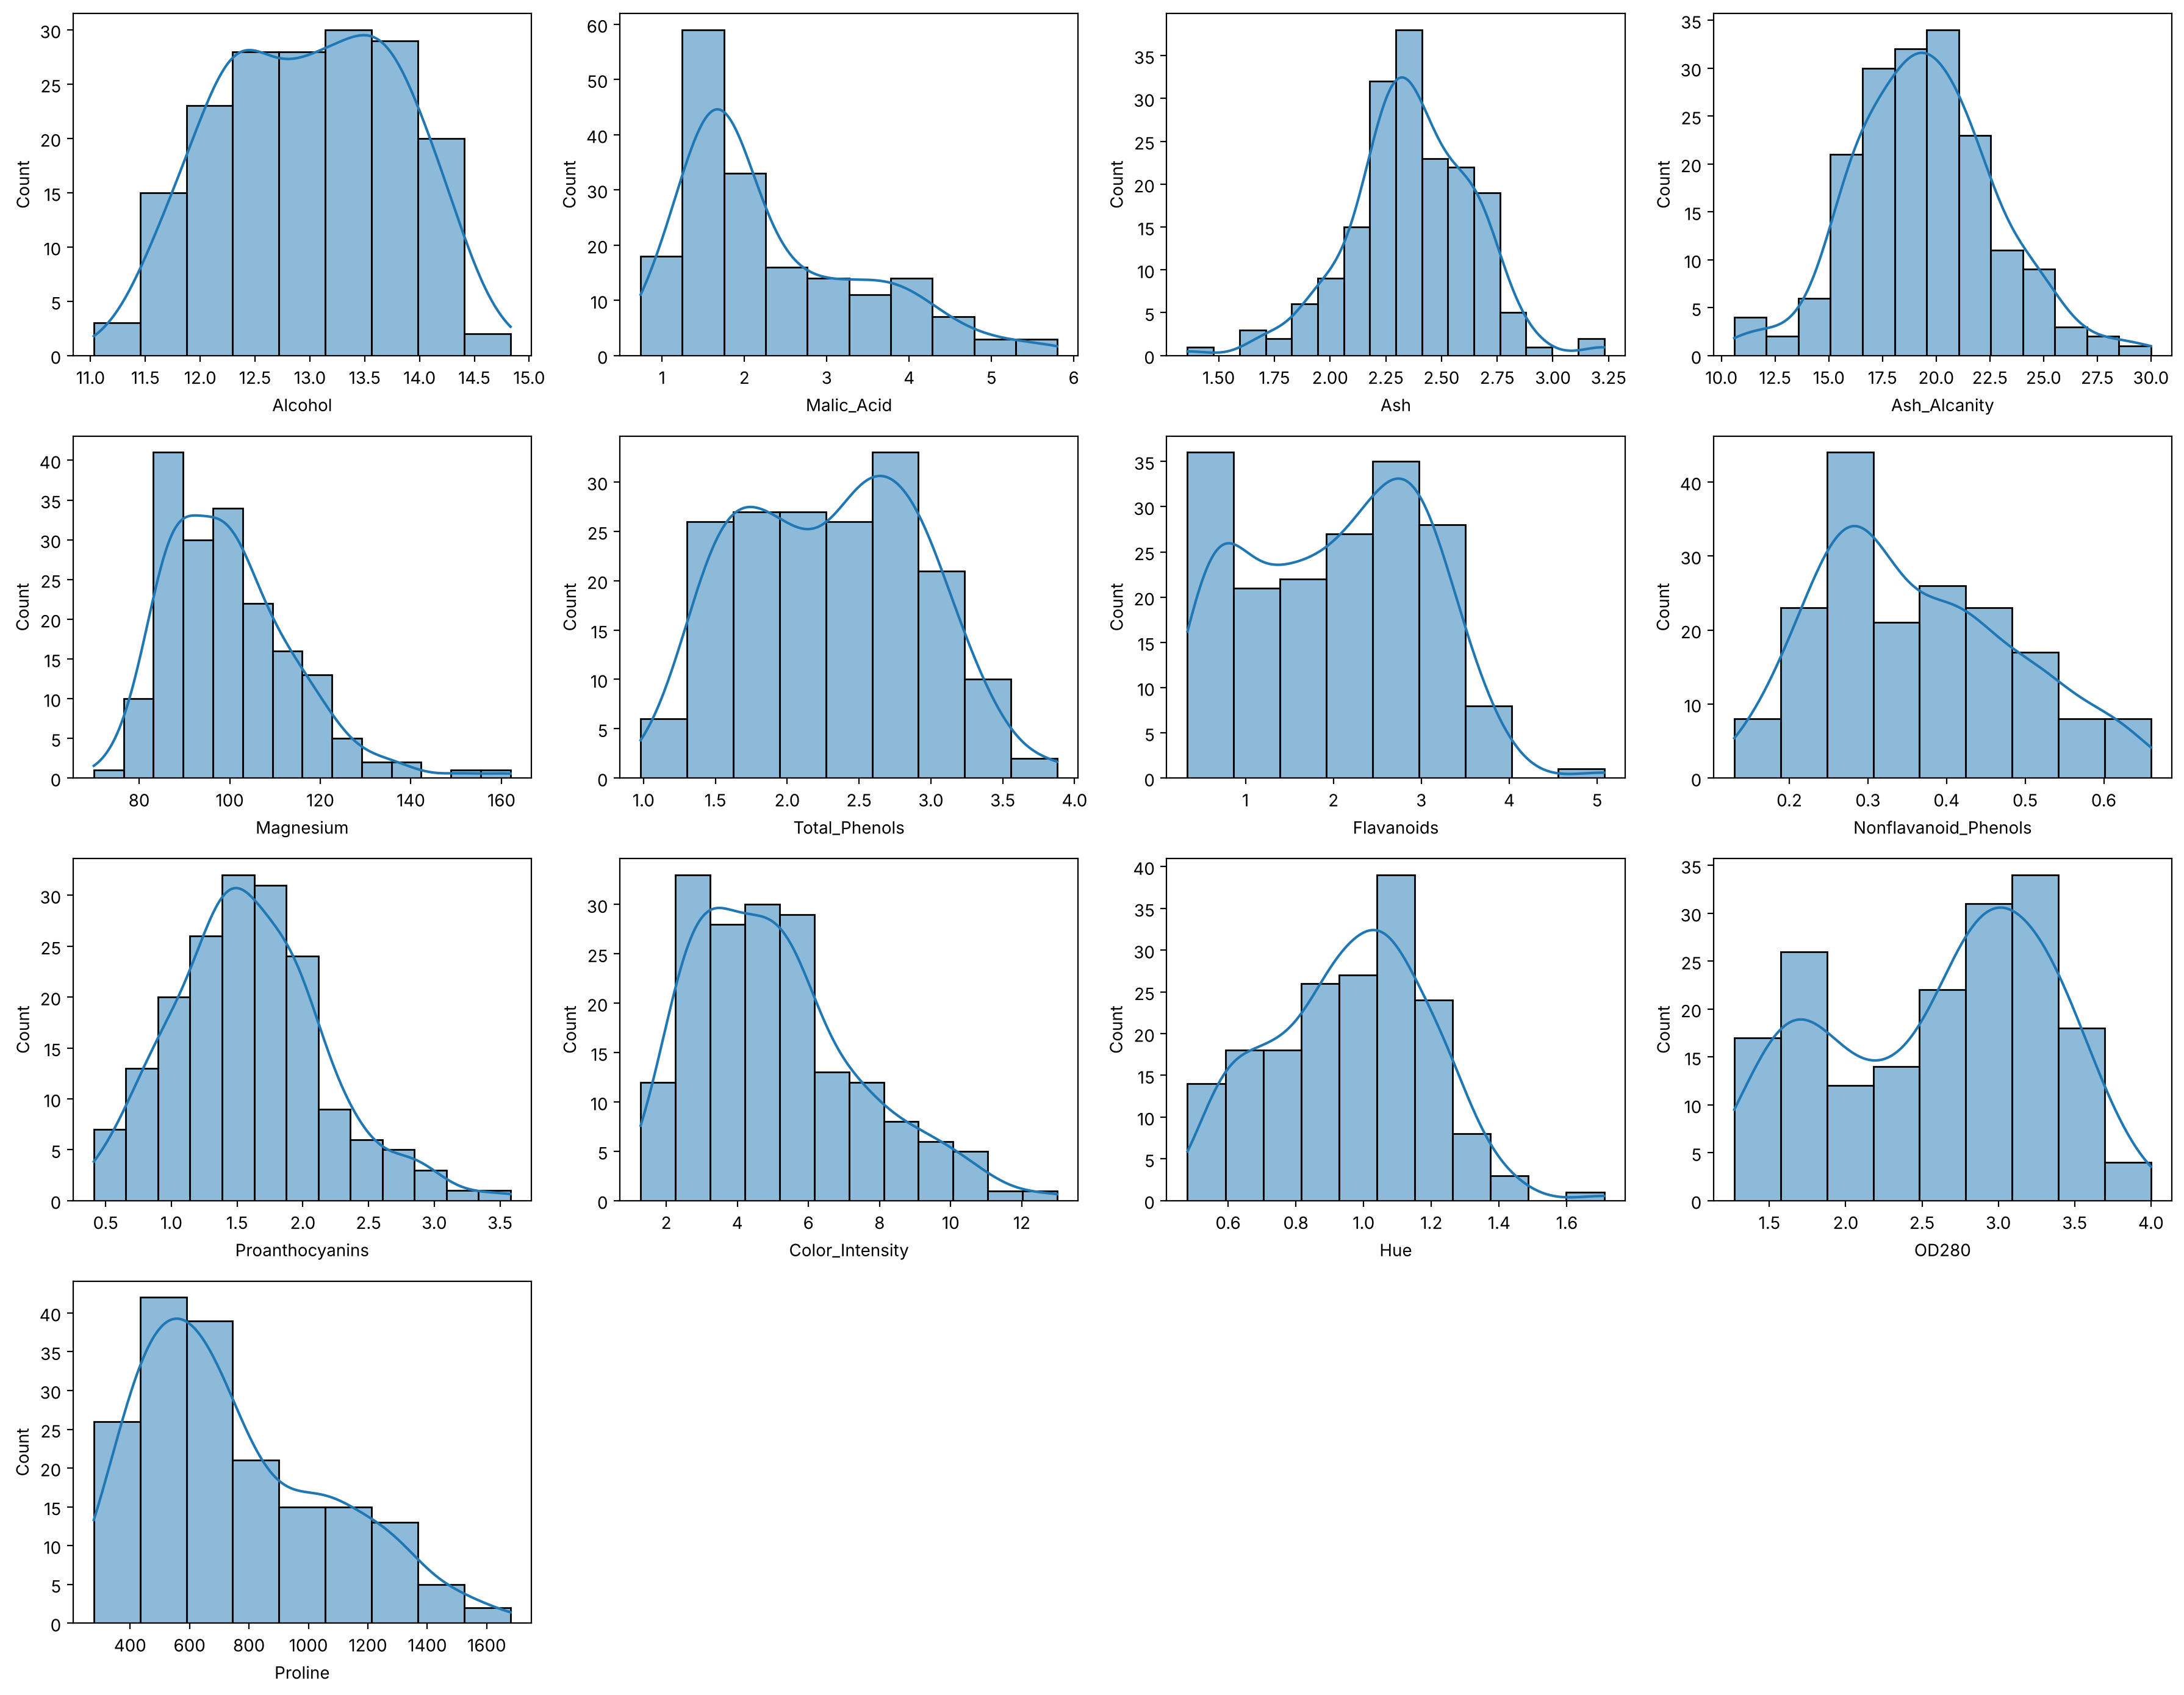

In [6]:
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, col in zip(axes.ravel(), df.columns):
    sns.histplot(df[col], kde=True, ax=ax)
for ax in axes.ravel()[len(df.columns):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

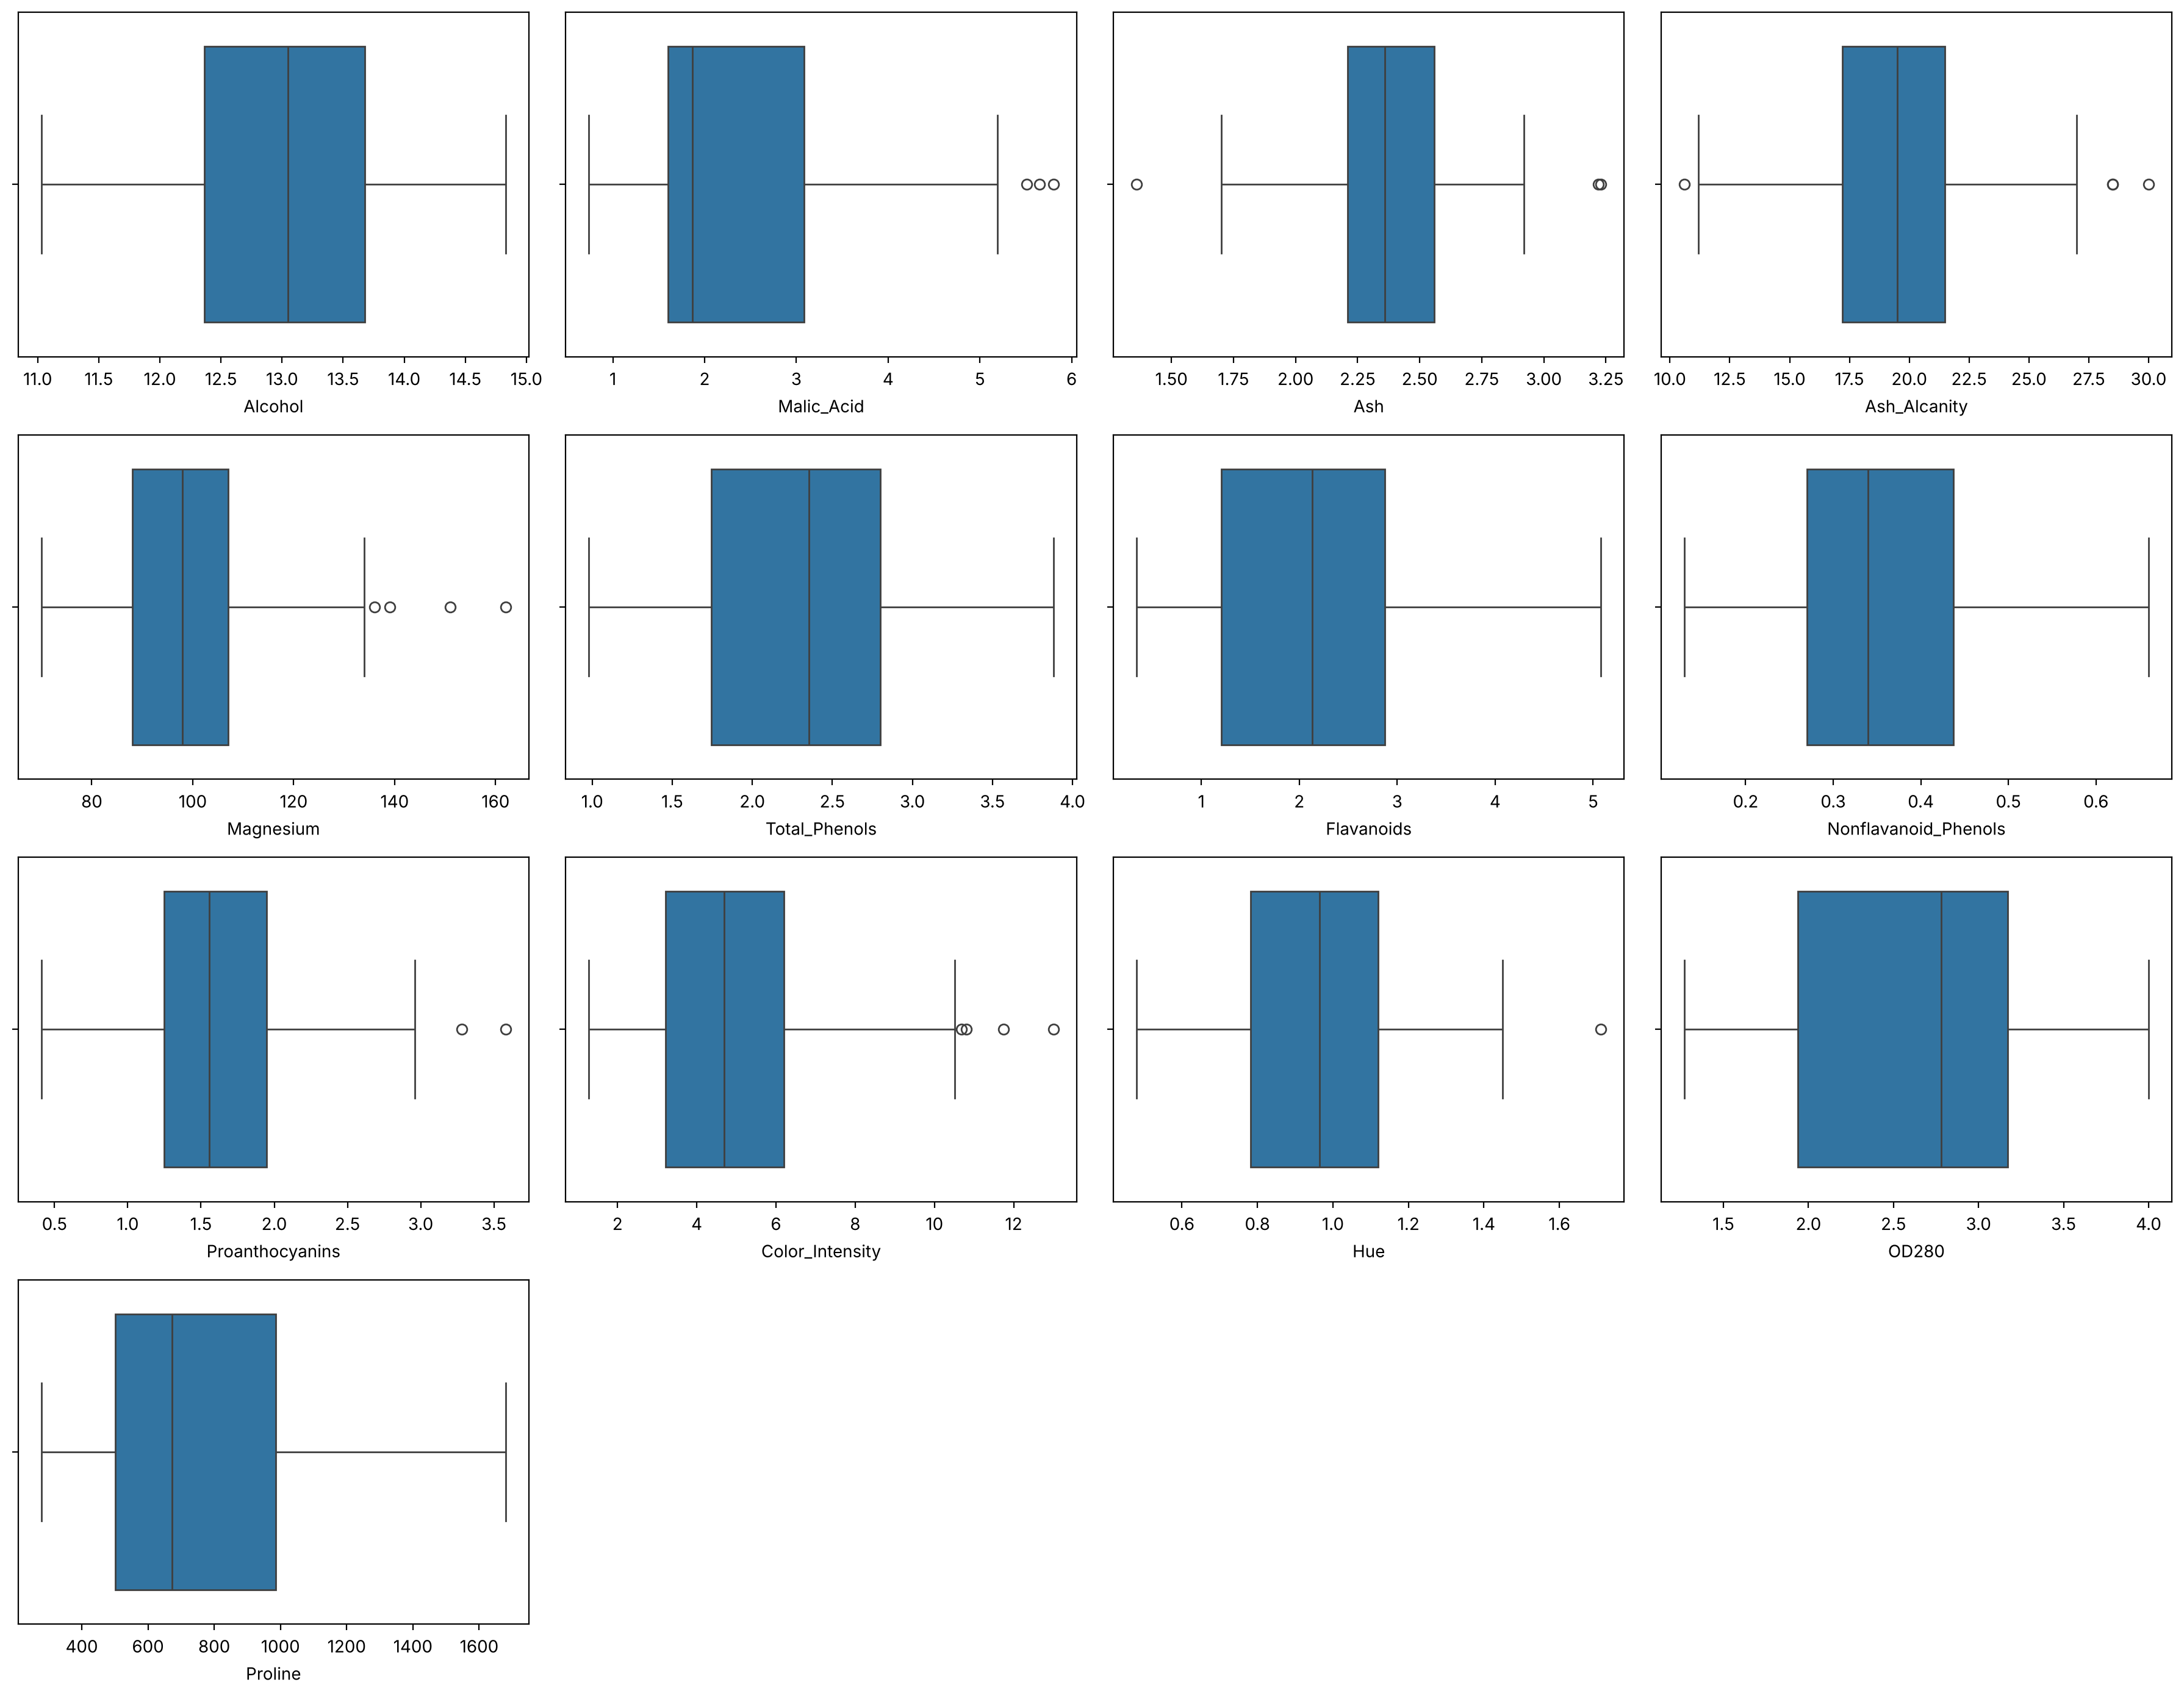

In [7]:
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, col in zip(axes.ravel(), df.columns):
    sns.boxplot(x=df[col], ax=ax)
for ax in axes.ravel()[len(df.columns):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

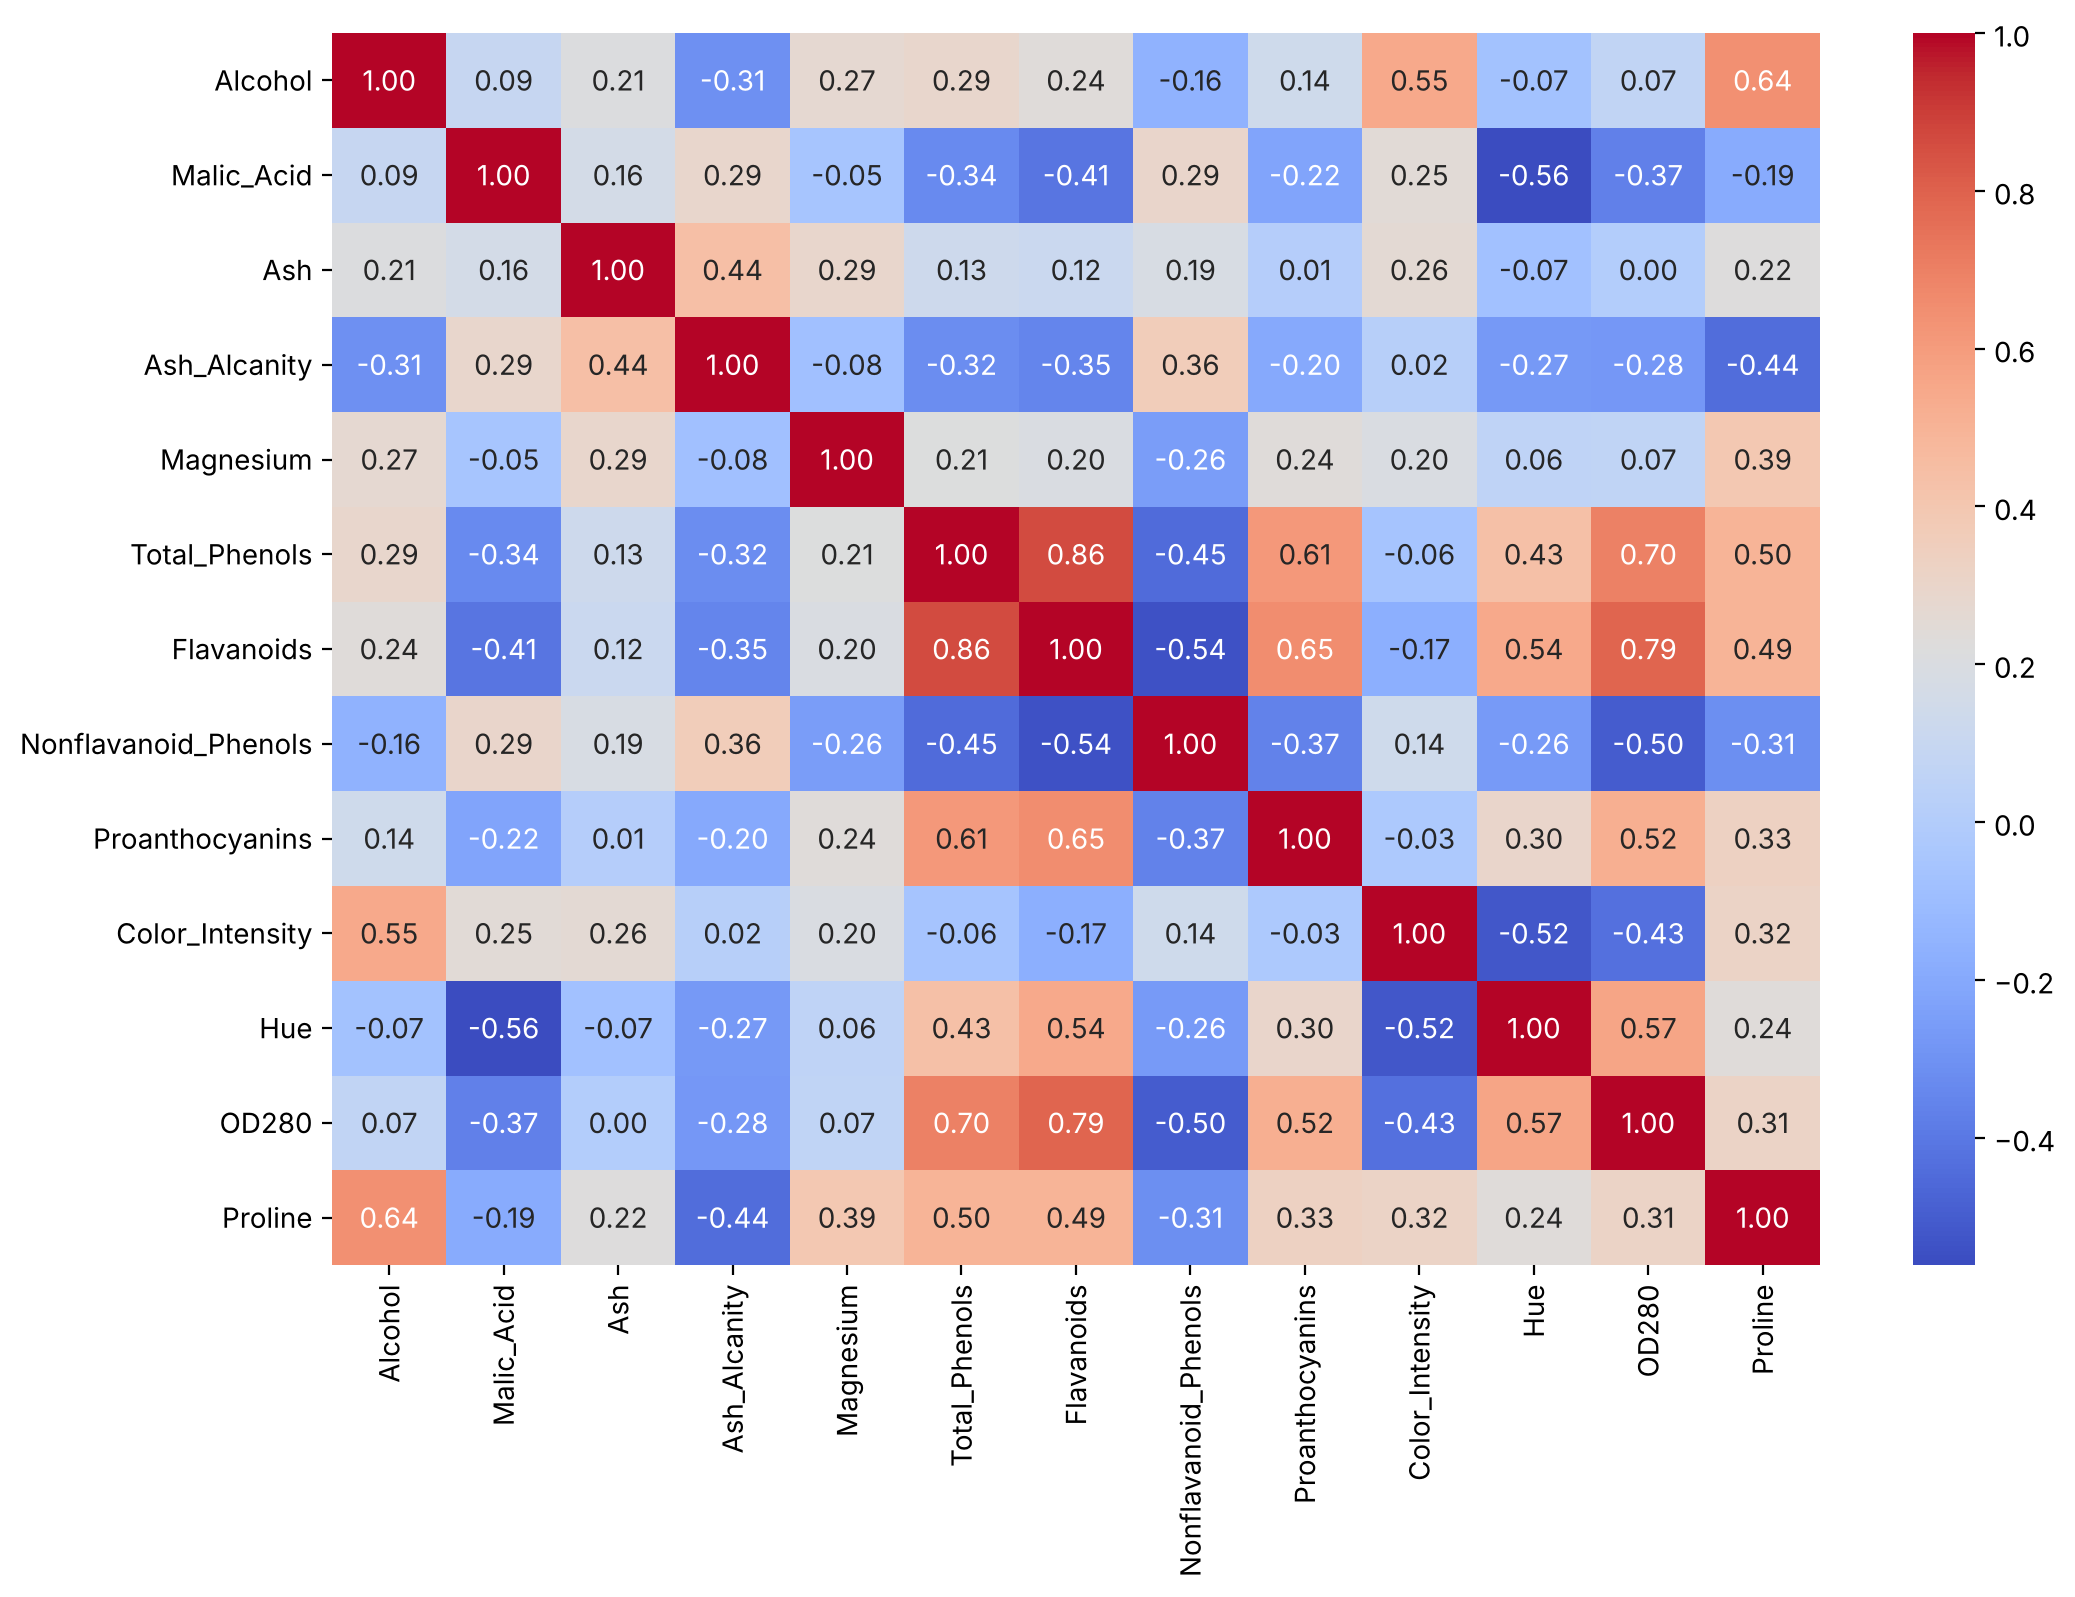

In [8]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

In [9]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)

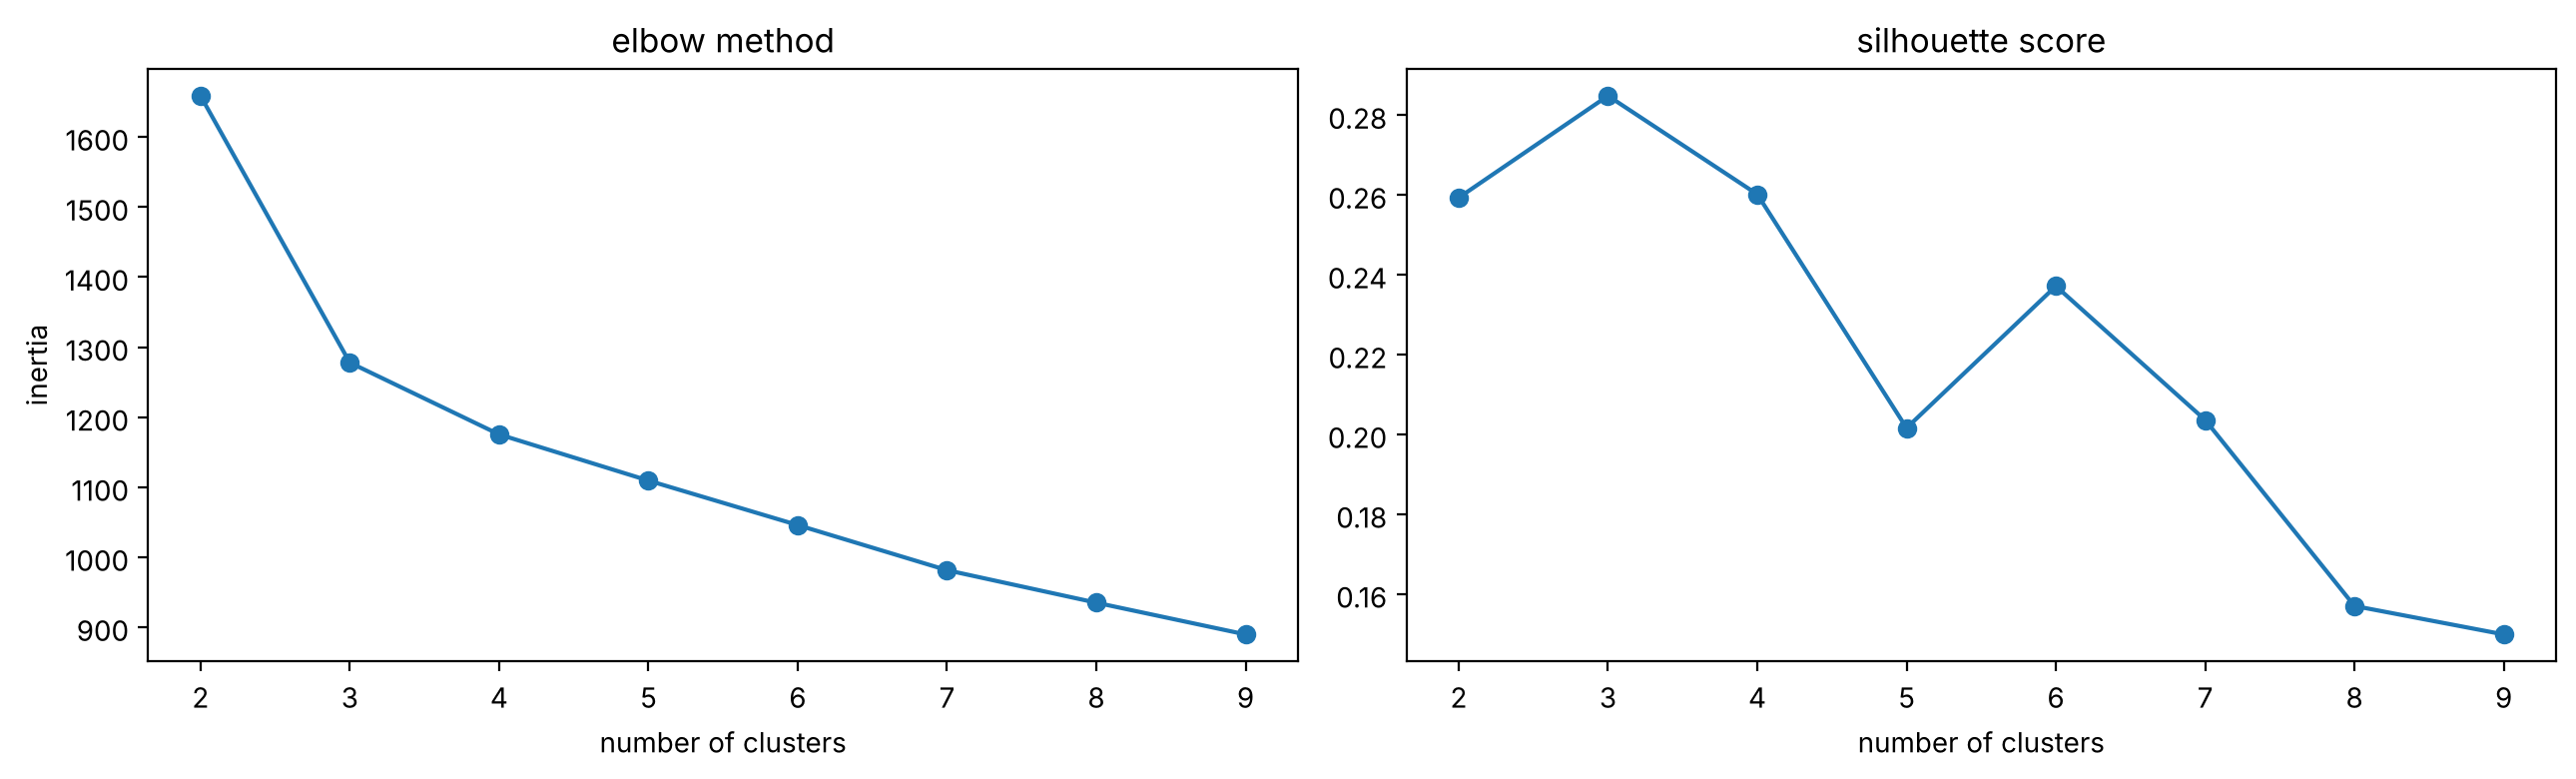

In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
k_range = range(2, 10)
inertias = []
silhouettes = []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(k_range, inertias, marker='o')
axes[0].set_title('elbow method')
axes[0].set_xlabel('number of clusters')
axes[0].set_ylabel('inertia')
axes[1].plot(k_range, silhouettes, marker='o')
axes[1].set_title('silhouette score')
axes[1].set_xlabel('number of clusters')
plt.tight_layout()
plt.show()

In [11]:
best_k = list(k_range)[int(np.argmax(silhouettes))]
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
df['Cluster'] = kmeans.fit_predict(X_scaled)
df['Cluster'].value_counts().sort_index()

Cluster
0    65
1    51
2    62
Name: count, dtype: int64

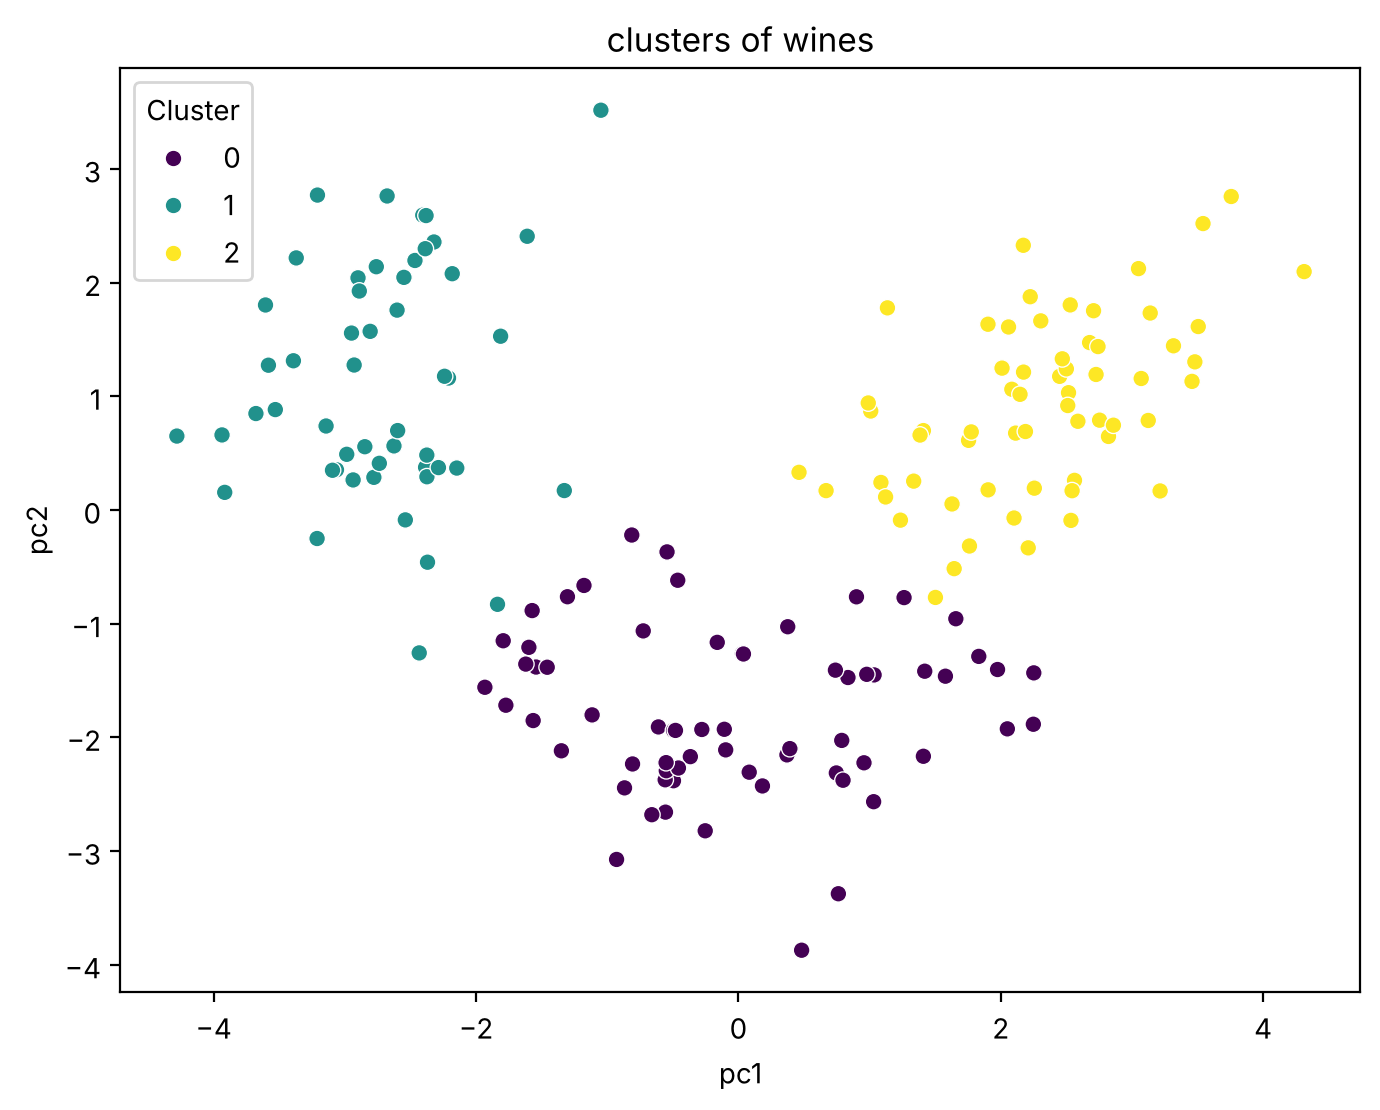

In [12]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=42)
pcs = pca.fit_transform(X_scaled)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=df['Cluster'], palette='viridis')
plt.title('clusters of wines')
plt.xlabel('pc1')
plt.ylabel('pc2')
plt.show()

In [13]:
df.groupby('Cluster').mean().round(2).T

Cluster,0,1,2
Alcohol,12.25,13.13,13.68
Malic_Acid,1.90,3.31,2.00
Ash,2.23,2.42,2.47
Ash_Alcanity,20.06,21.24,17.46
Magnesium,92.74,98.67,107.97
Total_Phenols,2.25,1.68,2.85
Flavanoids,2.05,0.82,3.00
Nonflavanoid_Phenols,0.36,0.45,0.29
Proanthocyanins,1.62,1.15,1.92
Color_Intensity,2.97,7.23,5.45


In [14]:
print(f'clusters: {best_k} | silhouette: {silhouette_score(X_scaled, df["Cluster"]):.2f}')

clusters: 3 | silhouette: 0.28
